# Accessing Magnetic Field Data from EarthScope Using MTH5

Space physics researchers often use long-running observatories such as [INTERMAGNET](https://intermagnet.org/) and [SuperMAG](https://supermag.jhuapl.edu/). Magnetic data are also available from magnetotelluric (MT) stations, which are typically deployed for days to weeks. Although these stations do not provide continuous long-term coverage, their greater spatial density enables new studies of geomagnetic phenomena.

[EarthScope](https://www.earthscope.org/) (formerly IRIS and UNAVCO) archives substantial electromagnetic (EM) data in addition to the seismological data for which it is best known. The following tools can help explore its holdings:

1. [Interactive Map](https://ds.iris.edu/gmap/)
2. [Station Service](http://service.iris.edu/fdsnws/station/docs/1/builder/) (URL builder for exploring metadata)
3. [Metadata Aggregator](https://ds.iris.edu/mda/) (MDA)
4. [Availability Service](http://service.iris.edu/fdsnws/availability/docs/1/builder/) (URL builder for exploring data holdings)

An example of programmatically querying EarthScope's magnetotelluric data holdings is available in the `earthscope_tests` branch of Aurora. This notebook uses the Interactive Map to identify magnetometer data in a region and time interval of interest.

This notebook demonstrates an MTH5 workflow for accessing EarthScope magnetic field data, motivated by making those data available to space physics researchers using PySPEDAS. Along the way, it includes examples of working with MTH5 and EarthScope metadata. For a simpler workflow that requests data in SI units, see the companion notebook, which wraps these steps in a call for PySPEDAS.

It is divided into the following sections:

0. Getting Started
1. Exploring Data Availability
2. Application to a Case Study
3. Request DataFrame 
4. Build MTH5 (metadata only)
5. Build MTH5 (with data)
6. Calibrating time series
7. Comparison of time series



# 0. Getting started

Install MTH5 from PyPI with pip:

> pip install mth5

or from conda-forge:
> conda install mth5

To run the companion notebook, install PySPEDAS with pip:
> pip install pyspedas

For installation instructions, see the [PySPEDAS documentation](https://pyspedas.readthedocs.io/).

### Confirm installation

Installing MTH5 also installs the `mt_metadata` package.

In [ ]:
import mt_metadata
import mth5
print(f"mt_metadata.__version__ {mt_metadata.__version__}")
print(f"mt_metadata.__file__ {mt_metadata.__file__}")
print(f"mth5.__version__ {mth5.__version__}")
print(f"mth5.__file__ {mth5.__file__}")

### Import required packages and modules

In [ ]:
from mt_metadata.timeseries.stationxml import XMLInventoryMTExperiment
from mth5.clients.fdsn import FDSN
from mth5.clients.make_mth5 import MakeMTH5
from mth5.mth5 import MTH5
from mth5.utils.helpers import initialize_mth5
import numpy as np
import pandas as pd
import pathlib

REDOWNLOAD = False
tutorial_dir_candidates = (
    pathlib.Path.cwd(),
    pathlib.Path.cwd() / "docs" / "tutorials",
    pathlib.Path.cwd() / "aurora-repo" / "docs" / "tutorials",
)
tutorial_dir = next(
    (
        candidate
        for candidate in tutorial_dir_candidates
        if (candidate / "earthscope_magnetic_data_tutorial.ipynb").is_file()
    ),
    pathlib.Path.cwd(),
)

import warnings
warnings.filterwarnings("ignore")

# 1. Exploring data at EarthScope

## Using the [Interactive Map](https://ds.iris.edu/gmap/)

The map provides a visual way to explore station coverage.

It is shown below:

In [ ]:
%%html
<iframe src="https://ds.iris.edu/gmap/" width="1200" height="1000"></iframe>

### Figure 1: The EarthScope geographic interface

Click **Update Map** in the upper-left corner to display station data. You can narrow results by location, time, data type, sample rate, and instrument orientation.

## FDSN formats

EarthScope is one of several organizations that use standards defined by the International Federation of Digital Seismograph Networks (FDSN), which specifies conventions for time-series data.

The [SEED manual](http://www.fdsn.org/pdf/SEEDManual_V2.4_Appendix-A.pdf) describes these conventions, including channel naming.

For the example here, we need only know two things:

1. EarthScope data are organized hierarchically: a network contains stations (physical observatories), and each station contains channels corresponding to individual instrument data streams.
2. A three-character code identifies each data stream: the first character indicates sample rate, the second indicates the measured field, and the third indicates orientation.

The main features of the interface will be illustrated for the purpose of magnetometer data.
- Magnetic data use the SEED instrument code `F`.
- The SEED manual specifies `N`, `E`, and `Z` orientations for magnetometer data; more recently, `1`, `2`, and `3` have also been used.
- Magnetic data use many sample rates, so a wildcard is useful in the sample-rate position. `?` matches one character, while `*` can match multiple characters; this example uses `?`.

Notes:
- Avoid wildcards in the third (component) position: `F` can also appear in station-health channels such as `VFP` (packet buffer usage).
- The map's **Channel** field accepts lists. To explore magnetometer data, enter `?F1, ?F2, ?F3, ?FN, ?FE, ?FZ`, as shown below.
- Most magnetometers record three components, so checking one numeric and one letter-based orientation (for example, `?F3, ?FZ`) is often sufficient to assess coverage.


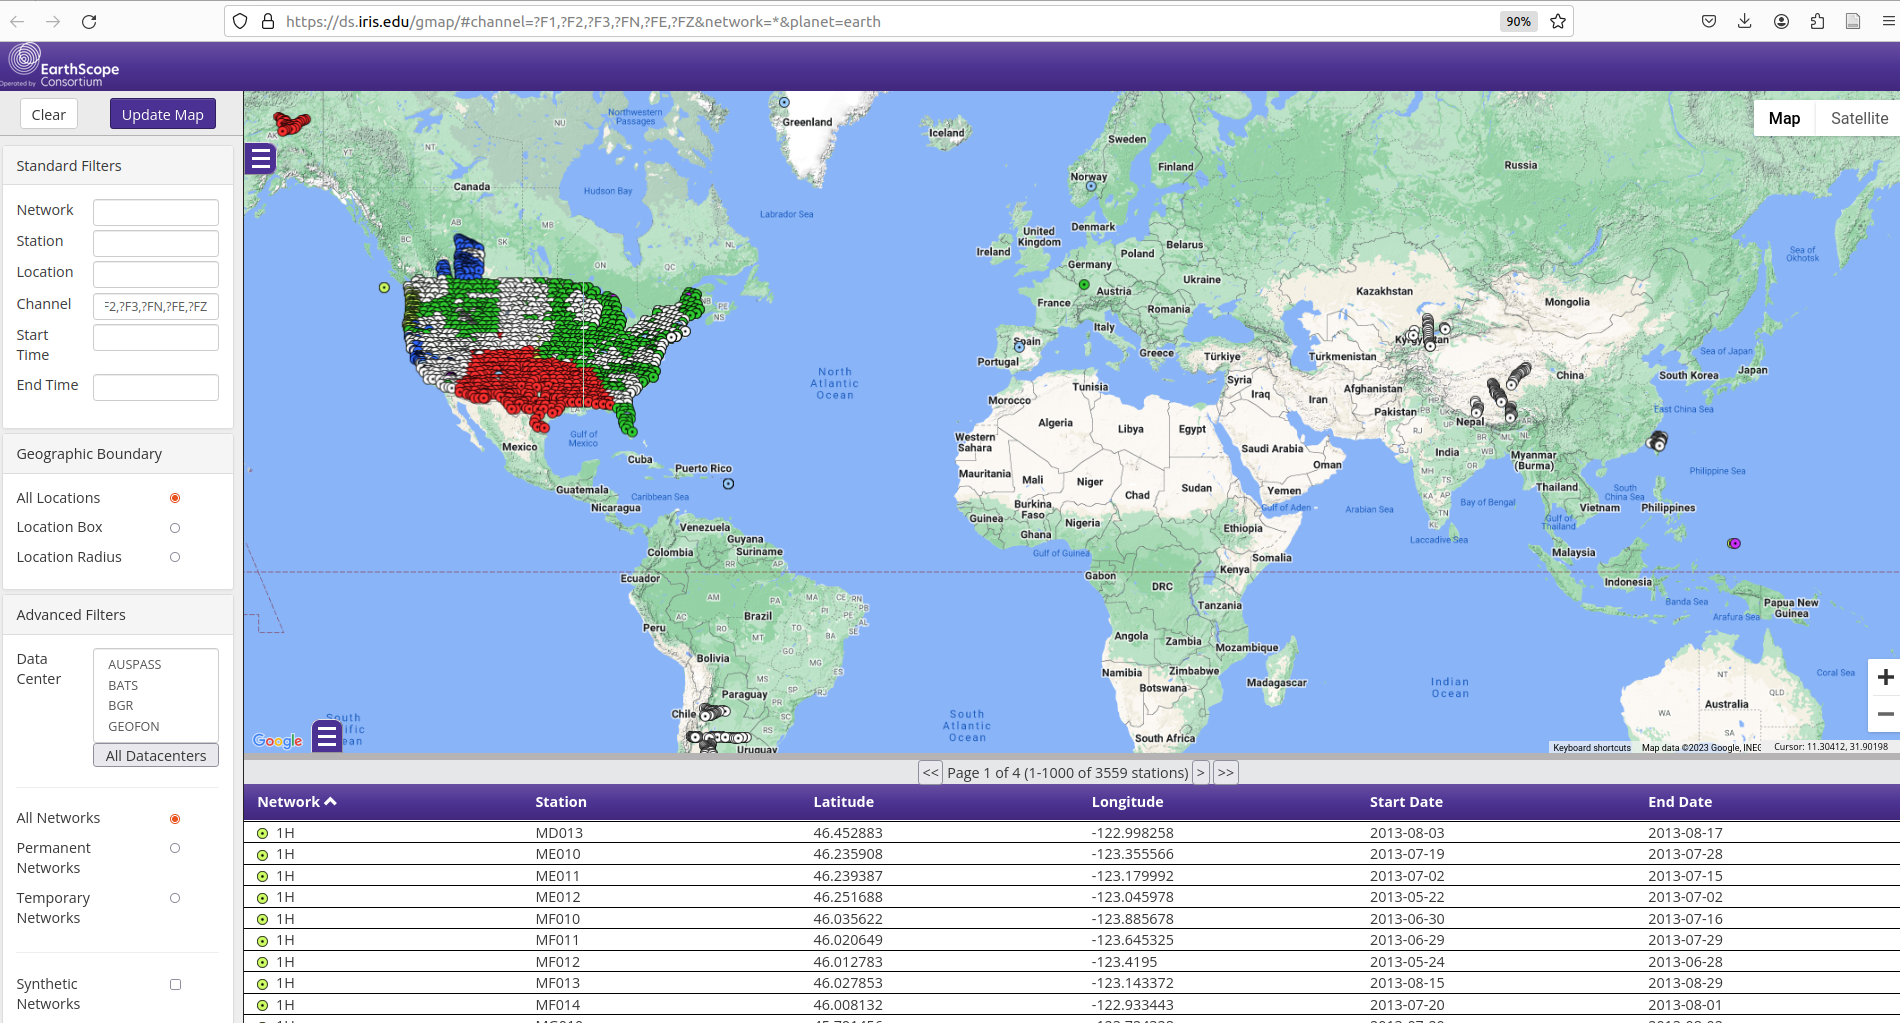


### Figure 2: Spatial distribution of the EarthScope magnetic dataset

Global data coverage returned from a query restricted only to magnetometer data.

## Exploring metadata availability with queries

### Station Service

The examples below show how to generate URLs programmatically to explore metadata availability. They use the base URL `http://service.iris.edu/fdsnws`. For more examples, see the EarthScope [URL Builder](http://service.iris.edu/fdsnws/station/docs/1/builder/).

Here is an example of a URL that lists metadata for all stations and channels with magnetic field data:

In [ ]:
# Specify the base URL  
fdsn_URL = "http://service.iris.edu/fdsnws"

# magnetic query using seed conventions
channels=['?FE', '?FN', '?FZ','?F1','?F2', '?F3', ]
channels = ','.join(channels)


# To obtain a list of all stations available:
channel_list_URL=f"{fdsn_URL}/station/1/query?cha={channels}&level=channel&format=text&includecomments=true&nodata=204"
print(f"channel_list_URL: {channel_list_URL}")

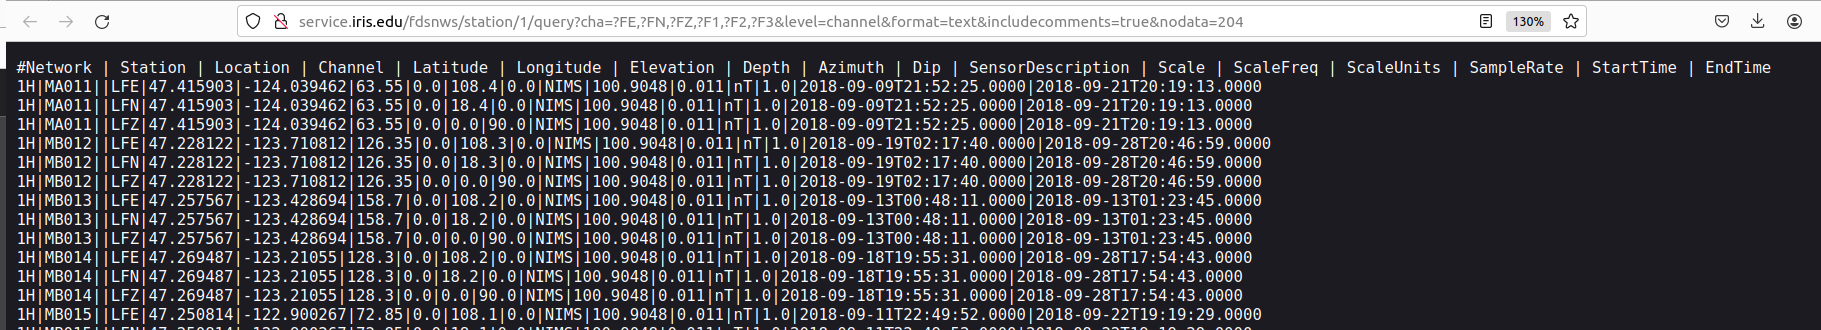

### Figure 3: Screengrab of station list associated with magnetic field data.  

As of December 2023, this webpage has 13228 lines!

### Availability Service

Note that each station is associated with a "Network" two-character code (first column in Figure above).  We can specify a network and see detail about the stations associated with this network, if we want to explore data availability via tabular summaries instead of using the map.  

Below is a code snippet for accessing a data coverage  (\"availability\") list for network "4P".

In [ ]:
network = "4P"
channels_str = f"{channels}"
print(channels_str.replace(" ",""))
channel_URL = f"{fdsn_URL}/availability/1/query?format=text&net={network}&cha={channels}&orderby=nslc_time_quality_samplerate&includerestricted=False&nodata=204" 
print(f"channel_URL:\n {channel_URL}")

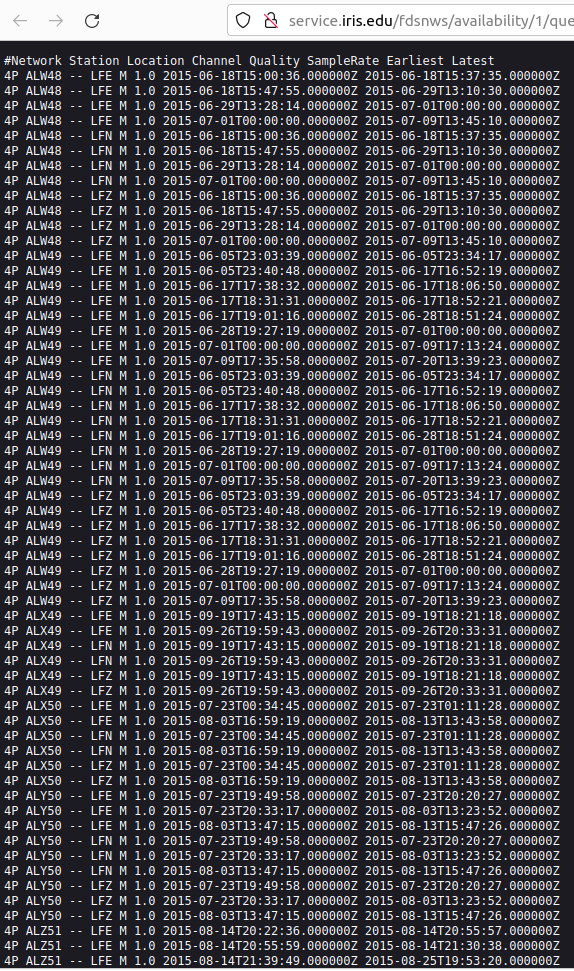

### Figure 4: Screengrab of availability URL for Network="4P"

### Metadata Aggregator (MDA)

EarthScope holdings can also be browsed hierarchically in the [Metadata Aggregator (MDA)](http://ds.iris.edu/mda/).
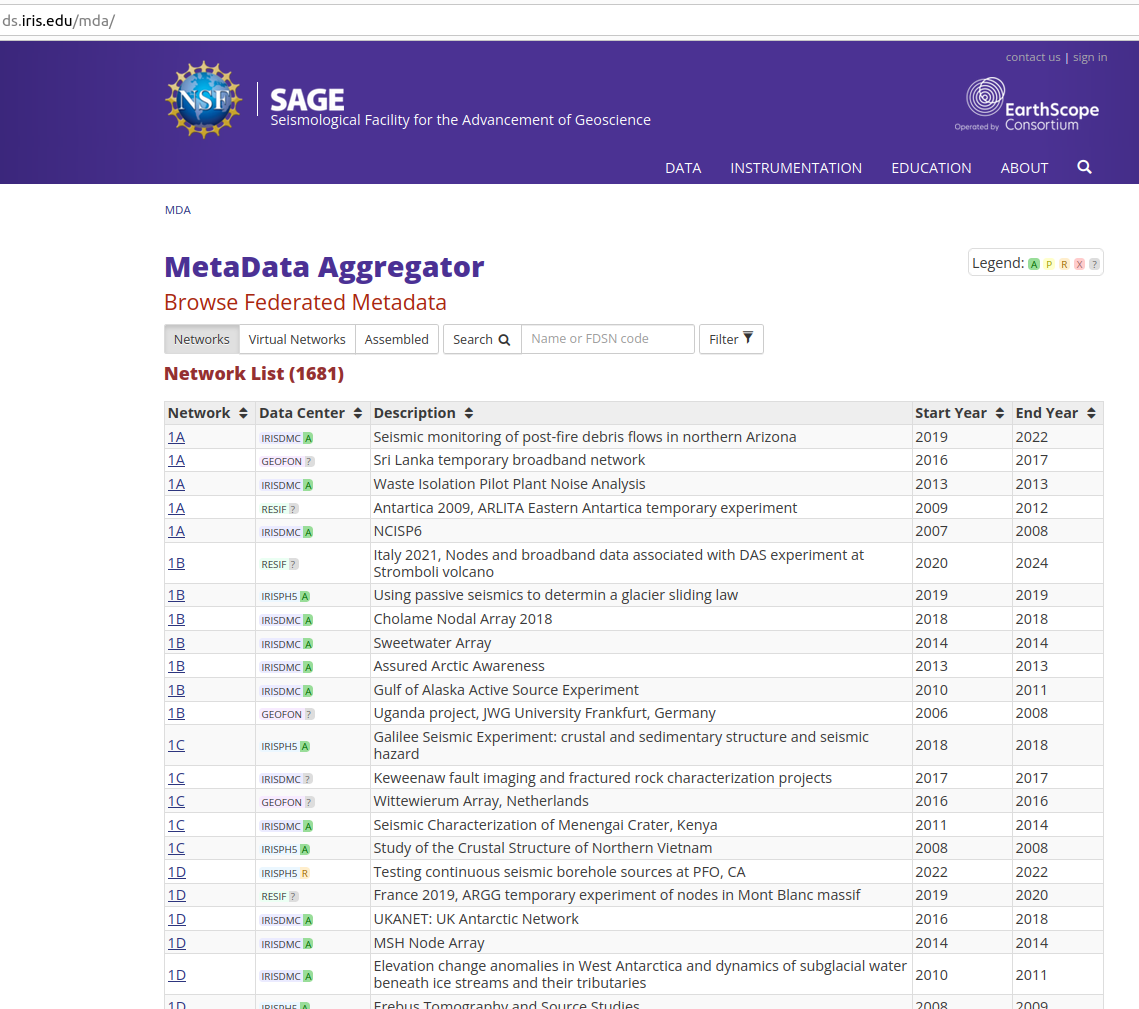


### Figure 5: EarthScope Metadata Aggregator (MDA) landing page.

# 2. Case study: comparison with a published observation
### Heyns et al. (2020)

Here we extract magnetic field data and compare it with the published observations.

We will use [Heyns et al. (2020)](https://agupubs.onlinelibrary.wiley.com/doi/full/10.1029/2020SW002557).

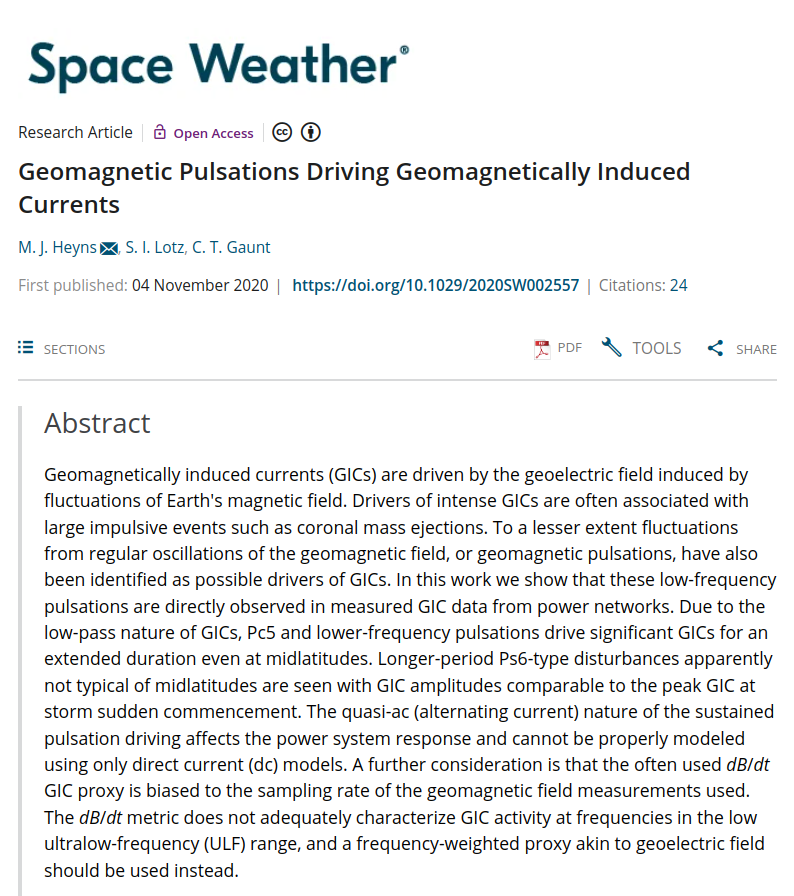

### Figure 6: Title and Abstract from Heyns et al. 2020

Figure 1 in the paper shows a magnetic-field time series.

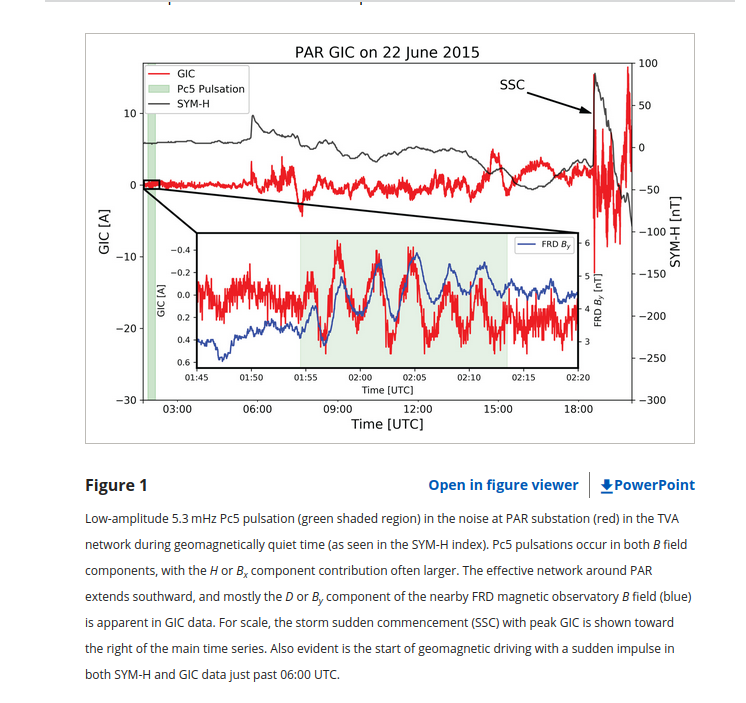

### Figure 7: Figure 1 from Heyns et al. (2020)
The inset in the lower panel shows 35 minutes of data from the FRD observatory (component B_y), which we will examine.

We can check whether nearby stations recorded the same fluctuations in the ambient magnetic field (the "event") by querying EarthScope data availability for this time interval.

## Identify relevant stations

Although FRD data are available through INTERMAGNET and the MTH5 global-observatory client, this case study first uses a nearby EarthScope station.

The USGS website lists the FRD coordinates (near Fredericksburg, Virginia):

https://www.usgs.gov/programs/geomagnetism/science/fredericksburg-frd

Station Id: FRD

Location: Corbin, VA

Latitude: 38.2047°N

Longitude: 77.3729°W

- First, locate Virginia on the map and center it. Then enter a date range around the day of interest:
[2015-06-01, 2015-06-30]
- You can constrain the search geographically with a bounding box or radius. The example below uses a bounding box.
- Extend the box by about 5 degrees in latitude and 10 degrees in longitude around FRD.

**EarthScope uses negative longitudes for locations west of the prime meridian.** See [NASA's explanation of longitude conventions](https://ccmc.gsfc.nasa.gov/requests/instant/ranges.php).

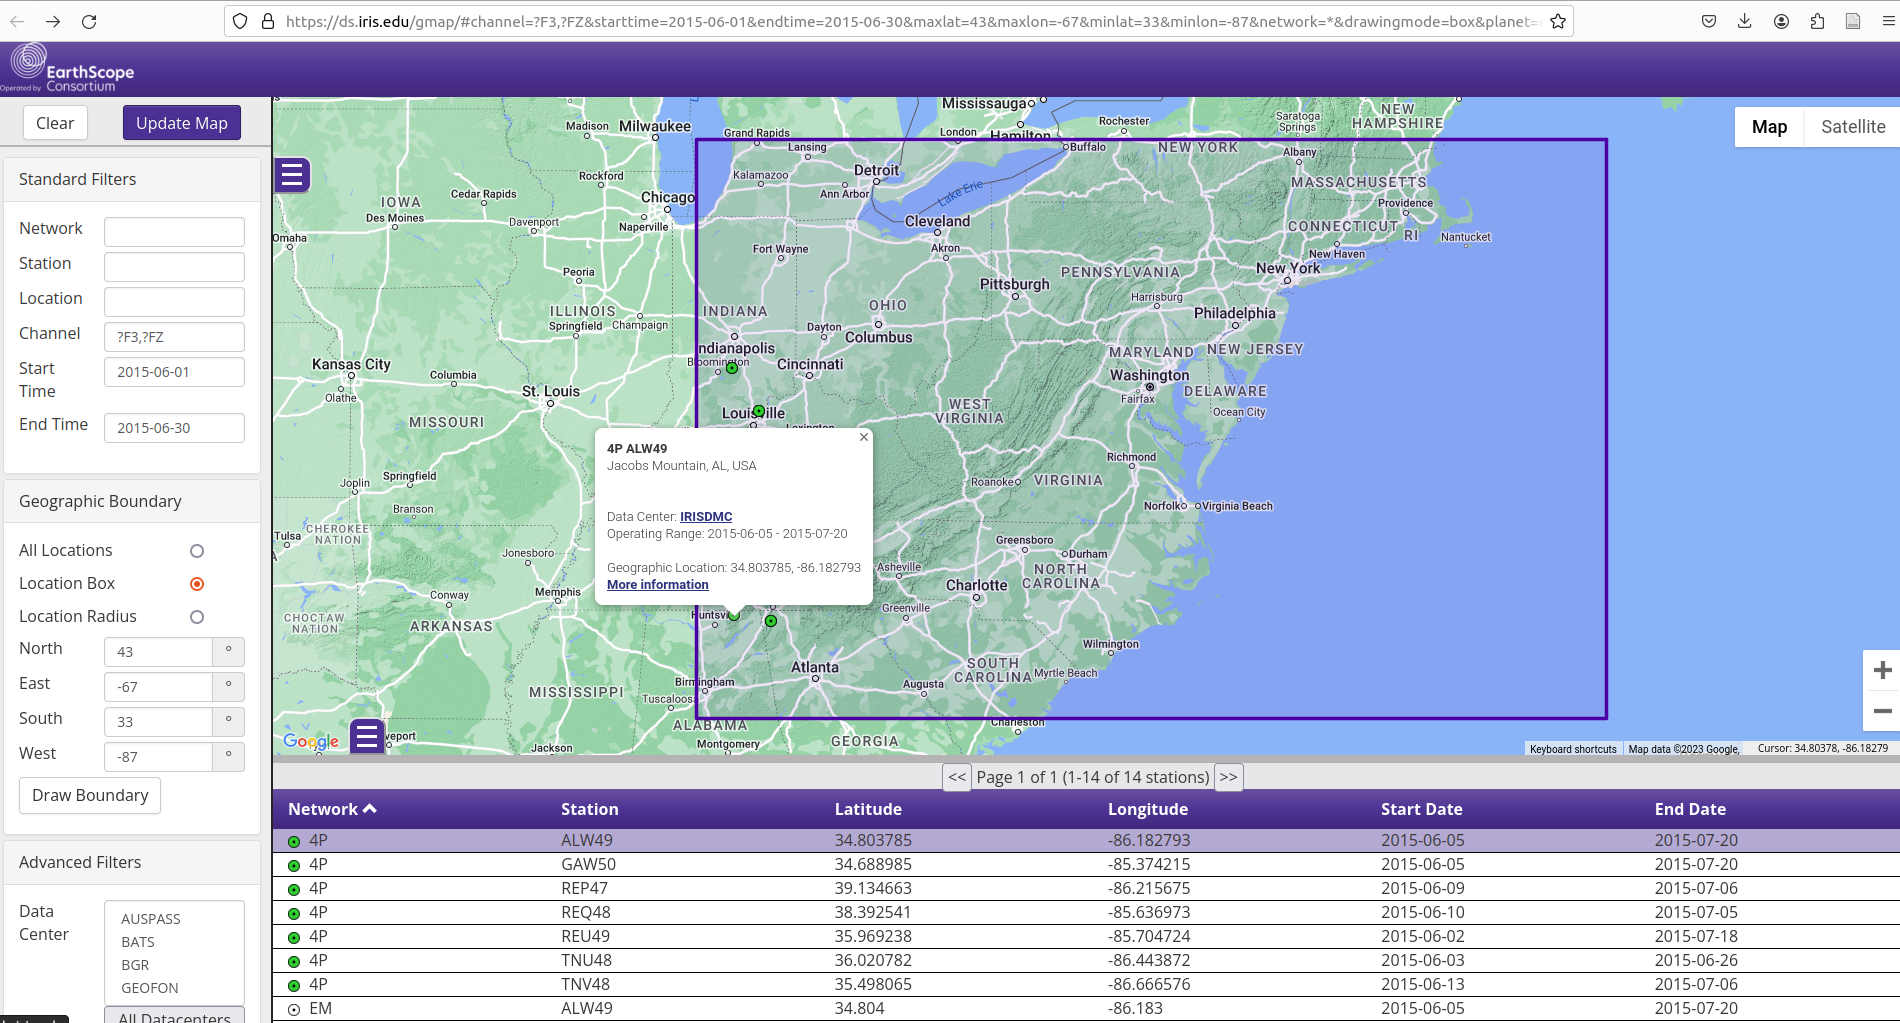

### Figure 8: Interactive map showing query results

Stations are shown with markers within the bounding box.  Stations are tabulated below the map (and the list is scrollable).  Clicking on a station marker makes a pop-up box, such as that shown for 4P ALW49.

### Select a single station

Let's pick the first one in alphabetical order.  Using the map we can readily see that there are metadata available in our time range, though we need to make sure that there is also data for the period.  Clicking a station makes a pop-up info box appear with further detail about the stations operating time range, and location.  Clicking on "more information" in this box takes us to the metadata aggregator (MDA) page, as shown below:


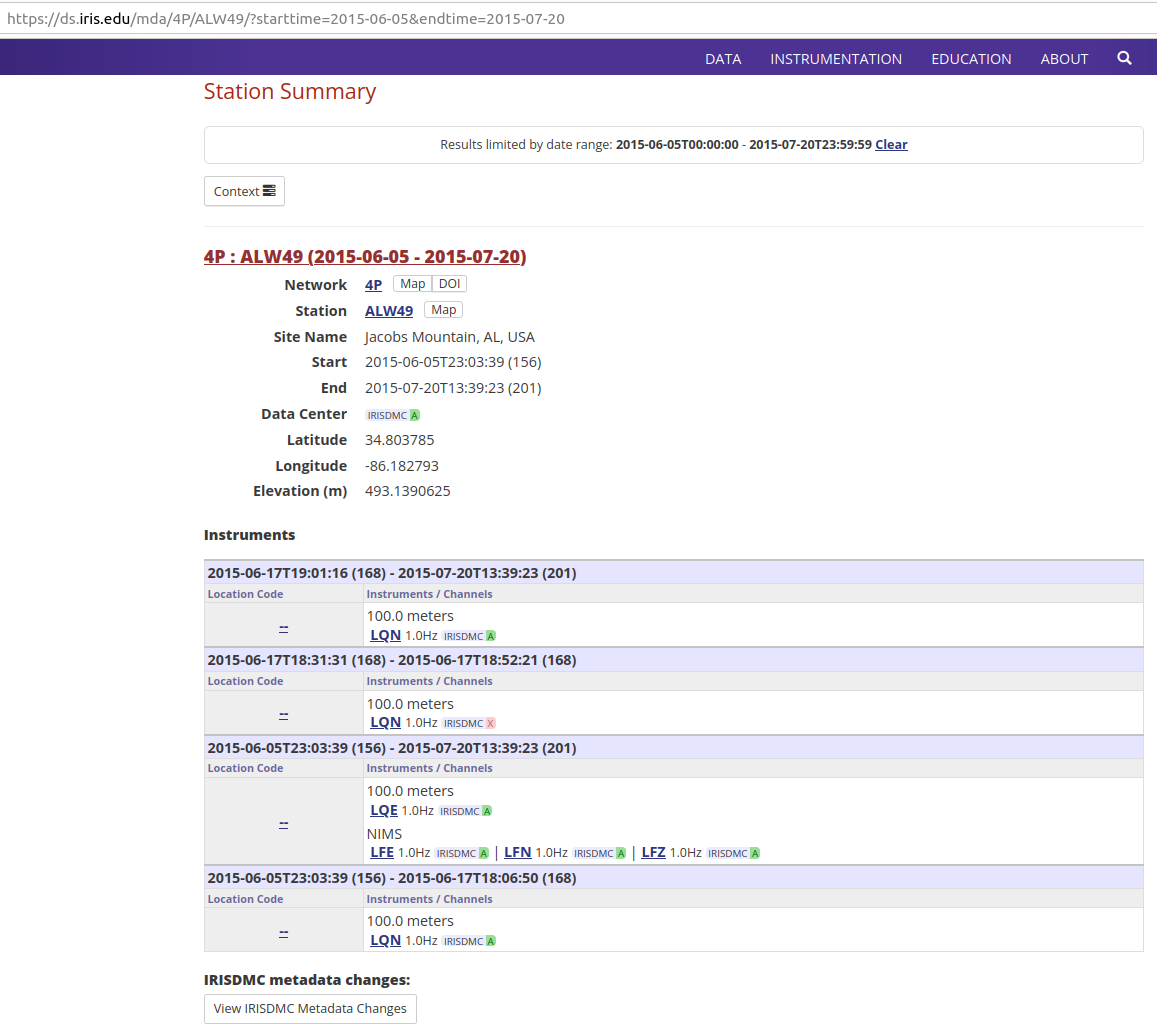

### Figure 9: MDA information for station ALW49

In [ ]:
# define the station
station = "ALW49"
# station = "TNU48"

# We can also query availability for a stion restrict availability by station:
station_availability_URL = f"{fdsn_URL}/availability/1/query?format=text&net={network}&sta={station}&cha={channels}&orderby=nslc_time_quality_samplerate&includerestricted=False&nodata=204" 
print(f"station_availability_URL: {station_availability_URL}")

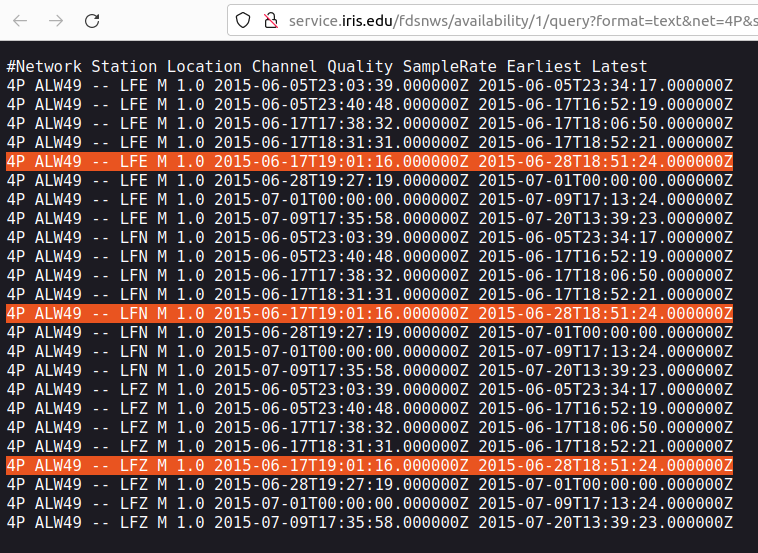

### Figure 10: Data availability for 4P.ALW49

This view shows the results of programmatically querying data availability for ALW49. The table contains several acquisition runs; select the relevant run or request the full interval, depending on your application. The highlighted rows show coverage for all three channels on June 22, 2015.

# 3. Define the request DataFrame

MTH5 provides an interface to download time series from FDSN clients.  The data requests are structured in tabular format, with one row for each requested time series.  The columns of the table are listed below:

In [ ]:
fdsn =FDSN()
fdsn.request_columns

Request tables can be loaded from CSV or generated programmatically as a pandas DataFrame.

The example below builds a request DataFrame. You can request only the interval of interest or a longer interval to keep more data in the local archive.

First, we retrieve and inspect EarthScope metadata before requesting the time-series data.

Note:
- As seen in Figure 10 above, the location field for this data is not defined, so we just set the location column of the request dataframe to the empty string: ""
- For short analyses (about 35 minutes here, compared with a multiweek data stream), request a longer interval than the one you will analyze. Frequency-domain calibration can create FFT/IFFT edge artifacts; padding the interval on both sides can reduce them.

In [ ]:
# Define the time interval of interest for future reference
time_interval_of_interest_start = "2015-06-22T01:45:00"
time_interval_of_interest_end = "2015-06-22T02:20:00"

In [ ]:
# Generate data frame telling FDSN data provided 
# Network, Station, Location, Channel, Startime, Endtime codes of interest
network = "4P"
channels = [ "LFE", "LFN", "LFZ", ]

# ALW49 RUN BOUNDS
if station == "ALW49":
    start = '2015-06-17T19:01:16'
    end = '2015-07-28T18:51:24'
    #start = time_interval_of_interest_start
    #end = time_interval_of_interest_end
elif station == "TNU48":
    start = '2015-06-14T15:13:54.000000Z'
    end = '2015-06-26T17:53:14.000000Z'
else:
    start = '2015-06-01T12:00:00'
    end = '2015-07-01T12:00:00'

request_list = []
for channel in channels:
    request = [network, station, "", channel, start, end]
    request_list.append(request)

print(f"Request List \n {request_list}")

# Turn list into dataframe
metadata_request_df = pd.DataFrame(request_list, columns=fdsn.request_columns)

# Optionally save to a csv:
metadata_request_df.to_csv(f"{station}_request.csv", index=False)

print(f"\n\n metadata_request_df \n ")
metadata_request_df

# 4. Build an MTH5 file (metadata only)

This has already been outlined in the MTH5 documentation, and the following is based on an [example in MTH5 for station CAS04](https://github.com/kujaku11/mth5/blob/master/docs/examples/notebooks/make_mth5_driver_v0.2.0.ipynb)

We start by building an inventory from the metadata.  The inventory is an obspy object, but an mt_metadata "experiment" object is the equivalent representation as shown below.  It is good practice to first inspect the experiment to verify the data availability.

In [ ]:
inventory, traces = fdsn.get_inventory_from_df(metadata_request_df, data=False)
translator = XMLInventoryMTExperiment()
experiment = translator.xml_to_mt(inventory_object=inventory)

In [ ]:
inventory

ObsPy provides tools to explore the inventory, but here we use the MTH5 experiment. Its hierarchy is analogous to FDSN, with two key differences:

1. MTH5 has a `survey` level, similar to FDSN's top-level `network`.
2. Above `survey` is `experiment`, which allows multiple networks to be stored in one archive.

In [ ]:
experiment

Although we requested a short interval, the experiment and its inventory contain information about the station's full history.

### Tabulated Metadata

We can optionally build a "dataless" mth5 from this inventory.  The dataless MTH5 can be useful because it provides programmatic access to a summary of the available data in a pandas DataFrame as shown below:

In [ ]:
# Initialize an mth5 container, packing the metadata contained in "experiment" variable
h5_path = "tmp.h5"
mth5_obj = initialize_mth5(h5_path, mode="w") # mode="a" allows you to aggregate results
mth5_obj.from_experiment(experiment)
mth5_obj.channel_summary.summarize()

summary_df = mth5_obj.channel_summary.to_dataframe()
summary_df

The channel summary provides a complete list of available data split into "Runs" -- contiguous blocks of available data for a particular channel.

This information can be a little dense as the archives grow ... You can look at a lower density form of data availability in the HDF5 file several ways. 

One way is to access the "run_summary" method of the "Station" group within the mth5 as shown in the snippet below:


In [ ]:
print(type(mth5_obj.stations_group))
mth5_obj.stations_group.station_summary

In [ ]:
station_obj = mth5_obj.get_station("ALW49")
station_obj.run_summary


Now we can see the time intervals available in a neat table, and we can also make a copy of this table and operate on it if we like. 
Here is an example snippet showing how to isolate the run containing the time interval of interest from the run summary:


In [ ]:
run_summary_df = station_obj.run_summary.copy(deep=True)


In [ ]:
run_summary_df["duration"] = run_summary_df["end"] - run_summary_df["start"]
run_summary_df

In [ ]:
cond1 = run_summary_df.start<pd.Timestamp(time_interval_of_interest_start)
cond2 = run_summary_df.end>pd.Timestamp(time_interval_of_interest_end)

run_of_interest = run_summary_df[cond1 & cond2]
run_of_interest

If the time period of interest fits inside a contiguous run, we can filter that row as above

# 5. Build an MTH5 file with data

Get the data for this run pulled down to our local machine

In [ ]:
client = "IRIS"
mth5_version = "0.1.0" 
# mth5_version = "0.2.0"

maker = MakeMTH5(
    mth5_version=mth5_version,
    client=client,
    mth5_filename="from_client.h5",
)
maker.client = client

In [ ]:
metadata_request_df

In [ ]:
# A channel summary can be transformed into a request dataframe for the specific runs of interest
# but you would need to install aurora for this
# from aurora.sandbox.mth5_channel_summary_helpers import channel_summary_to_make_mth5
# active_runs = ["b", ]
# if active_runs:
#    summary_df = summary_df[summary_df["run"].isin(active_runs)]  # summary_df[0:5]
# data_request_df = channel_summary_to_make_mth5(summary_df, network=network, verbose=True)

data_request_df = metadata_request_df.copy(deep=True)
data_request_df.start = run_of_interest.iloc[0].start
data_request_df.end = run_of_interest.iloc[0].end

In [ ]:
data_request_df.to_csv(f"{station}_request.csv", index=False)

In [ ]:
data_request_df

In [ ]:
mth5_filename = FDSN(mth5_filename="from_client.h5").make_filename(data_request_df)
mth5_path = tutorial_dir / mth5_filename
if REDOWNLOAD or not mth5_path.is_file():
    mth5_path = maker.from_fdsn_client(data_request_df, save_path=tutorial_dir)
else:
    print(f"Using existing MTH5 at {mth5_path}")

print(f"Made MTH5 at {mth5_path}")

In [ ]:
m = MTH5()

In [ ]:
m.open_mth5(mth5_path)

In [ ]:
channel_summary_df = m.channel_summary.to_dataframe()
channel_summary_df

You can now select the rows (12, 13, 14 zero-indexed) that contain the data of interest.  

The snippet below programmatically selects the row from the channel summary that contains the interval of interest:

In [ ]:
cond1 = channel_summary_df.start <pd.Timestamp(time_interval_of_interest_start).tz_localize("UTC")
cond2 = channel_summary_df.end >pd.Timestamp(time_interval_of_interest_end).tz_localize("UTC")

channels_of_interest = channel_summary_df[cond1 & cond2]
channels_of_interest

In [ ]:
hx_index = channels_of_interest[channels_of_interest["component"] == "hx"].index[0]
hy_index = channels_of_interest[channels_of_interest["component"] == "hy"].index[0]
hz_index = channels_of_interest[channels_of_interest["component"] == "hz"].index[0]

We can point at the data by using the "hdf5_reference" column of the data frame, for example:

In [ ]:
hx = m.from_reference(channel_summary_df.iloc[hx_index].hdf5_reference).to_channel_ts()
print(hx)

And here we can see the channel metadata:

In [ ]:
hx.channel_metadata

# 6. Calibrating time series


The following cell displays the filters EarthScope archived with the data:

In [ ]:
print(hx.channel_response)

Check that the server metadata filters match those in the station XML. The output above also shows the units of each filter.

**EarthScope continues to improve its data and metadata archives. For some historical data, filter input and output units are missing and appear as "unknown". In those cases, the data cannot be calibrated to SI units without manual intervention.**

In [ ]:
hx.channel_response.plot_response(np.logspace(-4, 1, 50))

In [ ]:
calibrated_hx = hx.remove_instrument_response(plot=True)

In [ ]:
calibrated_hx.channel_metadata

The `calibrated_hx` channel metadata differs subtly from `hx`: the units have changed from digital counts to nanotesla, and the `filter.applied` values have flipped for the first two filters. The third filter represents a sub-second time delay and is not applied by default.

The data associated with the calibrated ChannelTS can be accessed as follows:

In [ ]:
hx_xrts = calibrated_hx.to_xarray()
hx_xrts

Apply the same calibration to Hy and Hz:

In [ ]:
hy = m.from_reference(channel_summary_df.iloc[hy_index].hdf5_reference).to_channel_ts()
hz = m.from_reference(channel_summary_df.iloc[hz_index].hdf5_reference).to_channel_ts()

In [ ]:
calibrated_hy = hy.remove_instrument_response(plot=True)

In [ ]:
# We can suppress the calibrated plot by setting the keyword argument plot=False
calibrated_hz = hz.remove_instrument_response(plot=False)

The mean is subtracted before calibration. Many magnetometers used in magnetotelluric applications measure only changes in the field, not the static (DC) field. For a fluxgate magnetometer, as indicated by `sensor.type` above, the DC value is meaningful and can be added back.


In [ ]:
hy_xrts = calibrated_hy.to_xarray()
hz_xrts = calibrated_hz.to_xarray()


In [ ]:
#cond1 = hy_xrts.time >= pd.Timestamp(2015, 6, 22, 1, 45)
#cond2 = hy_xrts.time < pd.Timestamp(2015, 6, 22,2,20)
cond1 = hy_xrts.time >= pd.Timestamp(time_interval_of_interest_start)
cond2 = hy_xrts.time < pd.Timestamp(time_interval_of_interest_end)


In [ ]:
hy_day = hy_xrts.where(cond1 & cond2, drop=True)
print(hy_day)
hy_day.plot(color='g')

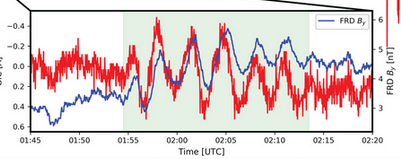

The time series are highly similar, as expected for a large-scale geomagnetic phenomenon that is coherent over hundreds of kilometers. Differences may reflect instrument variation and spatial variability; the stations are about 1,000 km apart, where spatial coherence may decrease.

## Bandpass Filtering the data

It is often the case the only certain frequency bands of data are desired, for example to remove high frequency spikes, or to suppress long term drift.  The calibration command supports the application of Butterworth band pass filters.  The user must define the "corners" of the band to admit as shown in the following example:

In [ ]:
hy = m.from_reference(channel_summary_df.iloc[hy_index].hdf5_reference).to_channel_ts()
calibrated_hy = hy.remove_instrument_response(plot=True, bandpass={"low":0.002, "high":0.05, "order":5})

# 7. Comparison of time series


In [ ]:
hy_day = hy_xrts.where(cond1 & cond2, drop=True)
print(hy_day)
hy_day.plot(color='g')

# 8. Access INTERMAGNET observatory data

In [ ]:
time_interval_of_interest_start

In [ ]:
start = time_interval_of_interest_start
end = time_interval_of_interest_end

start = "2015-06-22T00:00:00"
end = "2015-06-23T00:00:00"
# DECBAS=209690 in the FRD IAGA-2002 header: tenths of arcminutes east.
frd_baseline_declination_deg = (209690 / 10) / 60
if frd_baseline_declination_deg > 180:
    frd_baseline_declination_deg -= 360

intermag_request = {
    "observatory": ["FRD"],
    "type": ["adjusted"],
    "elements": [["X", "Y", "Z"]],
    "sampling_period": [1],
    "start": [start],
    "end": [end],
}
intermag_request_df = pd.DataFrame(intermag_request)
intermag_request_df

In [ ]:
maker = MakeMTH5()
intermagnet_h5 = maker.from_intermag(
    intermag_request_df,
    baseline_declination=frd_baseline_declination_deg,
)

# To keep all-NaN X/Y when available, explicitly disable fallback:
# intermagnet_h5 = maker.from_intermag(intermag_request_df, fallback_to_hdz=False)

In [ ]:
intermagnet_h5

In [ ]:
m2 = MTH5()
m2.open_mth5(intermagnet_h5)

In [ ]:
m2.channel_summary

In [ ]:
hy_frd = m2.get_channel("Fredericksburg", "sp1_001", "hy", survey="INTERMAG")

In [ ]:
hy_frd_ts = hy_frd.to_channel_ts()

In [ ]:
hy_frd_ts.data_array

In [ ]:
frd_time = hy_frd_ts.data_array.time
frd_in_interval = (frd_time >= pd.Timestamp(time_interval_of_interest_start)) & (
    frd_time < pd.Timestamp(time_interval_of_interest_end)
)
hy_frd_day = hy_frd_ts.data_array.where(frd_in_interval, drop=True)

In [ ]:
m2.close_mth5()

In [ ]:
# !rm -f intermag_FRD_XYZ.h5

The INTERMAGNET request above asks for X, Y, and Z. When the service reports those elements as all NaN, MTH5 logs the issue, retries with reported H, D, and Z, and converts them using the FRD baseline declination. The normal MTH5 download should now handle this case automatically. If the download fails, you can obtain the reference data from the [IAGA-2002 interface](https://imag-data.bgs.ac.uk/GIN_V1/GINForms2?observatoryIagaCode=FRD&publicationState=Best+available&dataStartDate=2015-06-22&dataDuration=1&submitValue=View+%2F+Download&request=DataView&samplesPerDay=second), or use the [notebook attached to MTH5 issue #188](https://github.com/IAGA-DVI-DataStandards/mth5/files/13999537/USGS_observatory_mth5.ipynb.gz) as a backup.

From the IAGA interface, select the IAGA-2002 format. The direct download URL for this example is:

https://imag-data.bgs.ac.uk/GIN_V1/GINServices?Request=GetData&format=Iaga2002&testObsys=0&observatoryIagaCode=FRD&samplesPerDay=second&publicationState=Best%20available&dataStartDate=2015-06-22&dataDuration=1&orientation=native

Save the file as `frd20150622vsec.sec` in the tutorial directory.

Then read it as follows:

In [ ]:
iaga_file = tutorial_dir / "frd20150622vsec.sec"
if not iaga_file.is_file():
    msg = f"{iaga_file} is missing. Download the data using the link in the cell above."
    raise FileNotFoundError(msg)

iaga_df = pd.read_csv(
    iaga_file,
    skiprows=22,
    sep=r"\s+",
    names=["DATE", "TIME", "DOY", "FRDH", "FRDD", "FRDZ", "FRDF"],
)
iaga_df["DATE_TIME"] = pd.to_datetime(iaga_df["DATE"] + " " + iaga_df["TIME"])


In [ ]:
iaga_df

The FRD file is reported in HDZ coordinates, while the INTERMAGNET request above asks for XYZ. For this day, the service returns H, D, and Z even when X, Y, and Z are requested, so the client retries with HDZ and derives the horizontal components.

The IAGA-2002 header defines `DECBAS` in tenths of arcminutes east. For FRD, `DECBAS=209690`, equivalent to 349.4833 degrees east or -10.5167 degrees wrapped to [-180, 180]. The file's D values are arcminutes of declination variation from this baseline; the BGS JSON service returns the variation in decimal degrees.

At each sample, geographic declination is the baseline plus the D variation. The horizontal field is transformed using `X = H*cos(D_total)` and `Y = H*sin(D_total)`; Z is unchanged. D is positive eastward. If the baseline is unknown, the client assumes zero degrees. Supply a station-specific `baseline_declination` to `from_intermag` when geographic components are needed; set `fallback_to_hdz=False` to leave unavailable X/Y values as NaN.

See the [IAGA element definitions](https://wdc.kugi.kyoto-u.ac.jp/element/eleexp.html). `X_bezpy` and `Y_bezpy` below use only the D variation (a magnetic-north-relative frame); X and Y use the baseline-corrected geographic direction.

In [ ]:
Y = iaga_df.FRDD
DECBAS_TENTHS_ARCMIN = 209690
DECLINATION_DEG = (DECBAS_TENTHS_ARCMIN / 10) / 60
if DECLINATION_DEG > 180:
    DECLINATION_DEG -= 360
DECLINATION_RAD = np.deg2rad(DECLINATION_DEG)

MIN_ARC_to_RAD = np.deg2rad(1 / 60)
D_to_RAD = MIN_ARC_to_RAD
D_TOTAL_RAD = DECLINATION_RAD + iaga_df.FRDD * D_to_RAD

In [ ]:
# D variation alone gives components relative to magnetic north.
iaga_df["X_bezpy"] = np.cos(np.deg2rad(iaga_df.FRDD/60.)) * iaga_df.FRDH
iaga_df["Y_bezpy"] = np.sin(np.deg2rad(iaga_df.FRDD/60.)) * iaga_df.FRDH

# Add the baseline declination to rotate into geographic X/Y.
iaga_df["X"] = np.cos(D_TOTAL_RAD) * iaga_df.FRDH
iaga_df["Y"] = np.sin(D_TOTAL_RAD) * iaga_df.FRDH

These are very similar in variation, but quite different in mean value:

In [ ]:
import matplotlib.pyplot as plt
import scipy.signal as ssig

In [ ]:
fig, ax = plt.subplots(2,1)
ax[0].plot(iaga_df.DATE_TIME, iaga_df.Y_bezpy, label="FRD Y geomag csys")
ax[0].plot(iaga_df.DATE_TIME, iaga_df.Y, label="FRD Y geographic csys")
ax[0].legend()
ax[1].plot(iaga_df.DATE_TIME, ssig.detrend(iaga_df.Y_bezpy,type="constant"), label="FRD Y geomag csys")
ax[1].plot(iaga_df.DATE_TIME, ssig.detrend(iaga_df.Y,type="constant"), label="FRD Y geographic csys")
ax[1].legend()
ax[0].set_title("Absolute Field Values for Y component")
ax[1].set_title("Mean subtracted Field Values for Y component")
fig.tight_layout()

In [ ]:
cond1 = iaga_df.DATE_TIME >= time_interval_of_interest_start
cond2 = iaga_df.DATE_TIME < time_interval_of_interest_end
sub_df = iaga_df[cond1&cond2]
print(len(sub_df))

In [ ]:
fig, ax = plt.subplots(1)
ax.plot(sub_df.DATE_TIME, ssig.detrend(sub_df.Y), label="FRD iaga")
ax.plot(
    hy_frd_day.time,
    ssig.detrend(hy_frd_day.data, type="constant"),
    label="FRD INTERMAGNET MTH5",
)
ax.plot(sub_df.DATE_TIME, hy_day.data, label="ALW49 mth5")
ax.legend()
ax.set_xlabel("UTC Time of day, 22 June, 2015")
ax.set_title("EarthScope ALW49 vs INTERMAGNET FRD (mean subtracted)")
ax.set_ylabel("nanoTesla")

In the above plot we can see that the data are highly similar but not identical.  Understanding the differences in the observed fields at the different stations and relating them to a model is a topic of ongoing investigation.

**Future Work** 

[ ] 1. Add an automated check warning the user when unknown filter units are encountered.
- Added some text around cell 33 warning the user about this.
- If filters are unknown is there a contact at EarthScope to request the info?
- The "enrich_dataframe" method from aurora (used in widescale tests) could be added to MTH5 for this